### rc_test6_silo

Implemented calculating of the 'complexity' measure. 
Tested against Merredin data and toy systems. 

- Queensland Government, & Australian Bureau of Metreorology. (1996). SILO - Australian climate data from 1889 to yesterday [Data set]. In Using spatial interpolation to construct a comprehensive archive of Australian climate data. https://doi.org/10.1016/S1364-8152(01)00008-1    

-- Produced plots of readout vector node weightages.     
-- Calculated consequent 'complexity' of predictions. 

--- Date:   July 2026

In [15]:
import urllib.request
import urllib.parse
import pandas as pd
import io
import numpy as np
import matplotlib.pyplot as plt
from numpy import trapezoid
import math


In [16]:
def collect_data(form,lat,lon,start,finish,username,password='apirequest'):
    """
    quering and requesting data from SILO using API
    """
    params = {'format': form,
              'lat': lat,
              'lon': lon,
              'start': start,
              'finish': finish,
              'username': username,
              'password': password
             }

    api_url = 'https://www.longpaddock.qld.gov.au/cgi-bin/silo' 
    url = api_url + '/DataDrillDataset.php?' + urllib.parse.urlencode(params)
    
    with urllib.request.urlopen(url) as remote:
        data = remote.read()
        body_str = data.decode('utf-8')
        
    return pd.read_csv(io.StringIO(body_str), skiprows=31, sep=r'\s+')


In [17]:
def clean_data(df):
    """
    converting requested dataset into usable pandas dataset
    - extracting dates in format dd/mm/yyyy
    - converting columns to numeric
    - computing cumulative growing degree days using tmin, tmax and tbase (10)
    """
    df = df.drop(index=0).reset_index(drop=True)
    df['Date2'] = pd.to_datetime(df['Date2'], format='%d/%m/%Y')

    # convert columns to numeric 
    for cols in df.columns:
        if cols != 'Date2':
            try:
                df[cols] = pd.to_numeric(df[cols])
            except (ValueError, TypeError):
                pass

    # extract year, month, day
    df['Year'] = df['Date2'].dt.year
    df['Month'] = df['Date2'].dt.month
    df['Day'] = df['Date2'].dt.day
    # apply GDD calculation
    df['T.Avg'] = (df['T.Max'] + df['T.Min']) / 2
    df['GDD'] = np.where(df['T.Avg'] >= 10, df['T.Avg'] - 10, 0)
    # find cumulative growing degree days
    df['GDD.C'] = df['GDD'].cumsum()
    
    return df

def prepare_data(df, by):
    """
    preparing rainfall and cumulative growing degree set variables 
    - perform smoothing on rainfall observations through rolling window average
    -
    - normalise rainfall observations
    - extract normalised rain and gddc vectors
    """

    clean = clean_data(df)
    # smooth rain values using rolling window average
    clean['Rain.Mean'] = clean.Rain.rolling(window=180,min_periods=1).mean()

    # if wanting to retain normal time based spacing (extracts a weekly point)
    if by == "Time":
        clean_rain = clean[['Rain.Mean']].values[::7]
        clean_gddc = clean[['GDD.C']].values[::7]
    else:
        # generate regular gdd poitns every 100 units
        clean_gddc = np.arange(0, clean.GDD.sum(), 100)
        # estimate rainfall at each of these gdd points
        clean_rain = np.interp(clean_gddc, clean["GDD.C"], clean["Rain.Mean"])

    normalised_rain = []
    min_val = min(clean_rain)
    max_val = max(clean_rain)
    diff = max_val - min_val # normalise through min-max scaling
    for x in clean_rain:
        normalised_rain.append((x - min_val) / diff)
    return np.array(normalised_rain).reshape(len(clean_gddc),1), clean_gddc.reshape(len(clean_gddc),1)



In [18]:

start_date = '19710101'
end_date = '20260327'

# Merredin (10092) - Kwinana East Port Zone
merre_data = collect_data('standard','-31.48','118.28',start_date,end_date,'email@gmail.com')
merre_rain, merre_gddc = prepare_data(merre_data, by = "")

# Northam (10111) - Kwinana West Port Zone
northam_data = collect_data('standard','-31.65','116.66',start_date,end_date,'email@gmail.com')
northam_rain, northam_gddc = prepare_data(northam_data, by="")

# Northampton (8100) - Geraldton Port Zone
nh_data = collect_data('standard','-28.36','114.63',start_date,end_date,'email@gmail.com')
nh_rain, nh_gddc = prepare_data(nh_data, by="")

# Esperance (9789) - Esperance Port Zone
esperance_data = collect_data('standard','-33.83','121.89',start_date,end_date,'email@gmail.com')
esperance_rain, esperance_gddc = prepare_data(esperance_data, by="")

# Albany (9500) - Albany Port Zone
albany_data = collect_data('standard','-35.03','117.88',start_date,end_date,'email@gmail.com')
albany_rain, albany_gddc = prepare_data(albany_data,by="")


In [19]:
class ESN:
    """
    N: number of nodes 
    d: average number of connections per node
    rho: spectral radius
    split: proportion of data to take as training  
    """
    def __init__(self, N, d, rho, input_scaling):
        self.N = N
        self.d = d
        self.rho = rho
        self.a = input_scaling


        # random, sparse, reservoir weights:
        ## connections between nodes decided by probability of d/N
        # sampling from normal distribution provides random weight values.
        Weights = np.multiply(
            np.random.binomial(size=(self.N,self.N), p=self.d/self.N, n=1),
            np.random.normal(size=(self.N,self.N)))
        
        # rescale so that rho = largest absolutel eigenvalue (maintaining echo state property)
        self.Vadj = Weights * (self.rho/np.max(np.absolute(np.linalg.eig(Weights)[0])))

        # input matrix: maps the scalar input to every node of the reservoir
        self.Vin = self.a * np.random.uniform(-1,1,size=(1, self.N))

        # bias matrix: bias added to each node's activation
        self.Vbias = np.random.uniform(-1,1,size=(1,self.N))

    def run_reservoir(self,input_data):
        """
        drive the reservoir using the input_data and return the state at every timestep
        states = (len(input_data), N)
        - comments keep track of matrix multiplications
        """
        states = np.zeros((len(input_data)+1, self.N)) # (timesteps x N)
        for i in range(1, len(input_data)+1): # start at 1 to access previous reservoir state
            states[i, :] = np.tanh(
                np.dot(states[i-1:i, :], self.Vadj) + # (1,N) x (N,N) = (1,N)
                np.dot(input_data[i-1:i], self.Vin) +  # (1,1) x (1,N) = (1,N)
                self.Vbias)
        return states[1:,:] # (timesteps x N), skip first row as it stays zero due to no input being processed. 
      

    def train(self, train_input, train_target, washout, beta=0.01):
        """
        fit the output weights
        - remove the initial washout period from the states and target 
        - compute Vout through ridge regression
        """
        train_states = self.run_reservoir(train_input)
        # removing the washout period 
        train_states = train_states[washout:,:] 
        train_target = train_target[washout:,]

        # using ridge regression to compute the output weights through training
        self.Vout = np.dot(
            np.linalg.pinv(np.dot(train_states.T,train_states) + beta*np.identity(self.N)), #(N,t) x (t,N) = (N,N) + (N,N)
                           np.dot(train_states.T, train_target)) #(N,t) x (t,1) = (N,1)
                           #Vout = (N,1)

        return self.Vout
                           

    def freerun(self, test_input, steps):
        """
        method to perform freerun prediction
        - train the reservoir computer on some testing input data 
        - following training, the readout prediction replaces the input data
        - ESN will form predictions just using previous predictions, with no new information being processed.  
        """
        readout = self.run_reservoir(test_input) 
        freerun_states = np.zeros((steps, self.N))
        freerun_states[0,:] = readout[-1,:]
        for i in range(1, steps):
            freerun_states[i, :] = np.tanh(np.dot(freerun_states[i-1:i, :],self.Vadj) + #(1,N) x (N,N) = (1,N)
                                           np.dot(np.dot(freerun_states[i-1:i], self.Vout), self.Vin) + 
                                           self.Vbias) # the prediction replaces input_data[i-1:i]
                                           
        return np.dot(freerun_states, self.Vout)
                     

    def predict(self, test_input, test_target,washout=10):
        """
        run reservoir on test data and map states to predictions
        - remove initial washout period from states and testing input
        - compute Root Mean Squared Error of predictions 
        """
        test_states = self.run_reservoir(test_input)

        # apply trained linear readout
        predictions = np.dot(test_states, self.Vout)

        return predictions, test_states
    
    def metrics(self, test_input, test_target, washout=10):
        """
        method to return computed Root Mean Squared Error (RMSE) and readout vector to plot.
        - generate predictions
        - compute RMSE 
        """
        predictions, test_states = self.predict(test_input, test_target)
        rmse = np.sqrt(((predictions[washout:,] - test_target[washout:,])**2).mean())


        return predictions, rmse, self.Vout



In [20]:
def splitting_data(rain,gddc,step):
    """
    function to split rainfall and cumulative growing degree days by step size
    80% of data for training, 20% for testing
    """
    # step to decide how far prediction goes
    train_size = int(len(rain) * 0.8)
    train_input = rain[:train_size-step]
    train_target = rain[step:train_size]
    test_input = rain[train_size:-step]
    test_input_x = gddc[train_size:-step]
    test_target = rain[train_size+step:]
    test_target_x = gddc[train_size+step:]

    return train_input, train_target, test_input, test_input_x, test_target, test_target_x

def plotting_data(x_values, test_actual, test_predictions, location, step, time):
    """
    function to plot the resulting predictions against the actual data
    - now adjusted to take in both gdd spacing and time spacing
    """
    plt.plot(x_values,test_actual, label = 'actual_values',color='blue',)
    plt.plot(x_values, test_predictions, label='predicted',color='green',alpha=0.6)
    if time == True:
        plt.xlabel('Time in Days')
        title = 'Reservoir Computer Prediction of Rainfall against Days for \n' + str(location) + ' at ' + str(step) + ' Steps'
        plt.title(title)
    else:
        plt.xlabel('Cumulative Growing Degree Days (°C Days)')
        title = 'Reservoir Computer Prediction of Rainfall against Cummulative GDD. for \n' + str(location) + ' at ' + str(step) + ' Steps'
        plt.title(title)
    plt.ylabel('Standardised Rain (mm)')
    plt.title(title)
    plt.legend(['Actual Values', 'Prediction'])
    plt.savefig(f'{location}_time={time}_step={step}')
    plt.show()


def calculate_metrics(esn, rain, gddc, step, washout=100):
    """
    function to generate ESN-based predictions and compute RMSE, 
    also returns readout vector to see node weightages assigned during training. 
    """
    train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
    esn.train(train_input, train_target, washout=washout)
    predictions, rmse, vout = esn.metrics(test_input, test_target)

    return rmse, vout # return only rmse and readout vector. 

def rc_for_location(esn, location, rain, gddc, step, plotting, time=False, washout=100):
    """
    function run the ESN prediction and return RMSE  with a plot if requested.
    """
    train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
    esn.train(train_input, train_target, washout=washout)
    rain_pred, rmse = esn.predict(test_input, test_target)
    if plotting == True:
        plotting_data(test_target_x[10:], test_target[10:], rain_pred[10:], location=location, step=step, time=time)

    return rmse


def rc_with_freerun(esn, location, rain, gddc, step, freerun_steps, time=False):
   train_input, train_target, test_input, test_input_x, test_target, test_target_x = splitting_data(rain, gddc, step)
   esn.train(train_input, train_target, washout=100)
   free_run_test = esn.freerun(train_target, freerun_steps)

   plt.plot(test_input[:freerun_steps], label = 'actual_values',color='blue',)
   plt.plot(free_run_test, label='predicted',color='green',alpha=0.6)
   if time == True:
       plt.xlabel('Time in days')
       plt.title(f'Freerun Prediction of Rainfall against days at Step {freerun_steps} for Merredin')
   else:
       plt.xlabel('Cumulative Growing Degree Days (°C Days)')
       plt.title(f'Freerun Prediction of Rainfall against Cumulative Growing Degree Days\n at Step {freerun_steps} for Merredin')

   plt.ylabel('Standardised Rain (mm)')
   plt.legend(['Actual Values', 'Freerun Prediction'])
   plt.show()

   return free_run_test

## complexity of predictions for assorted locations

In [21]:
np.random.seed(123)

esn = ESN(300,10,0.9,1.0)

rmse, vout = calculate_metrics(esn, 'Merredin', merre_rain, merre_gddc, step=1)
sorted_vout = np.sort(vout.ravel()) # sort the nodes in ascending weightage 


abs_area = trapezoid(np.sort(np.abs(vout.ravel()))) # calculate the area under the curve of node weightages
print(abs_area) # this is the 'complexity' of the nodes. 


plt.plot(np.log(np.sort(np.abs(vout.ravel()))))
plt.title('Log Magnitude of Nodes used for 1 step Prediction of Merredin')
plt.xlabel("Node Rank")
plt.ylabel("Log Magnitude")
plt.savefig('Merredin_Complexity')
plt.show()


TypeError: calculate_metrics() got multiple values for argument 'step'

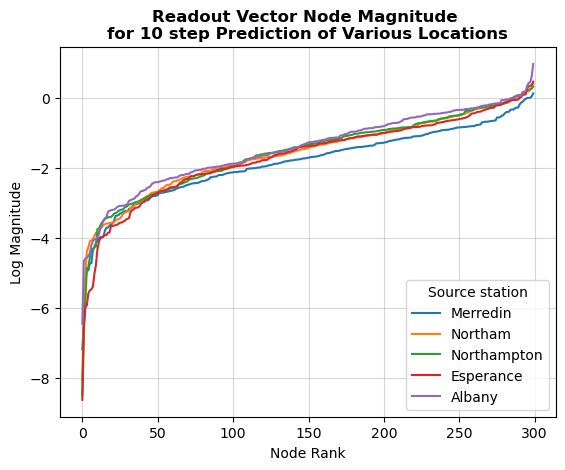

In [ ]:
# plot to showcase varying complexity of assorted locations when forming predictions at step = 10
merre_rmse, merre_vout = calculate_metrics(esn, 'Merredin', merre_rain, merre_gddc, step=10)
northam_rmse, northam_vout = calculate_metrics(esn, 'Northam', northam_rain, northam_gddc, step=10)
northam_rmse, northam_vout = calculate_metrics(esn, 'Northam', northam_rain, northam_gddc, step=10)
nh_rmse, nh_vout = calculate_metrics(esn, 'Northampton', nh_rain, nh_gddc, step=10)
esp_rmse, esp_vout = calculate_metrics(esn, 'Esperance', esperance_rain, esperance_gddc, step=10)
alb_rmse, alb_vout = calculate_metrics(esn, 'Albany', albany_rain, albany_gddc, step=10)

vouts = {
    'Merredin': merre_vout,
    'Northam': northam_vout,
    'Northampton': nh_vout,
    'Esperance': esp_vout,
    'Albany': alb_vout,
}


for name, v in vouts.items():
    plt.plot(np.log(np.sort(np.abs(v.ravel()))), label=name)
plt.title('Readout Vector Node Magnitude \nfor 10 step Prediction of Various Locations', fontweight="bold")
plt.xlabel("Node Rank")
plt.ylabel("Log Magnitude")
plt.legend(title='Source station')
plt.grid(alpha=0.5)
plt.savefig('VariousLoc_Complexity')


## complexity of predictions for logistic map
-- testing the complexity measure for the logistic map toy system

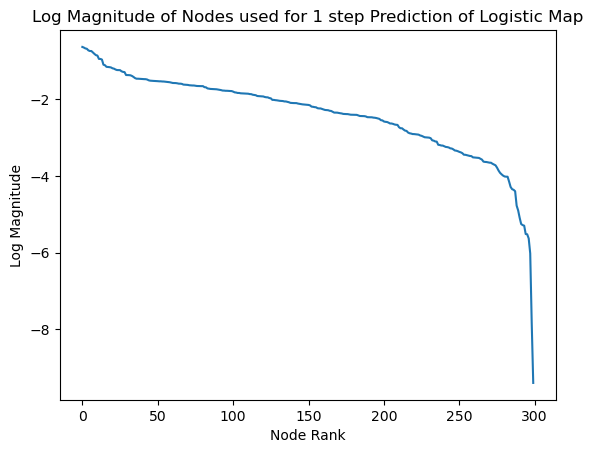

In [ ]:
np.random.seed(123)


def logistic_map(r,x0,iterations):
    # r: parameter value
    #x0: starting value
    #iterations: number of vals 

    x=np.zeros(iterations)
    x[0] = x0

    for k in range(iterations-1):
        
        x[k+1] = r * x[k] * (1-x[k])
    return x

#time = 100
example = np.array(logistic_map(3.9,0.1,1000))
example = example.reshape(-1,1) # reshaping the array into a 2d array
log_rmse, log_vout = calculate_metrics(esn, 'Logistic Map', example, np.arange(0,1000, dtype=int), step=1)
plt.plot(np.log(np.sort(np.abs(log_vout.ravel()))[::-1]))
plt.title('Log Magnitude of Nodes used for 1 step Prediction of Logistic Map')
plt.xlabel("Node Rank")
plt.ylabel("Log Magnitude")
plt.savefig('LogMap_Complexity')
plt.show()

## complexity of predictions for lorenz system
-- testing the complexity measure for the lorenz system toy system
-- complexity is broken down for each of the 3 variables of the lorenz system 

z-val area = -23.855385377109805


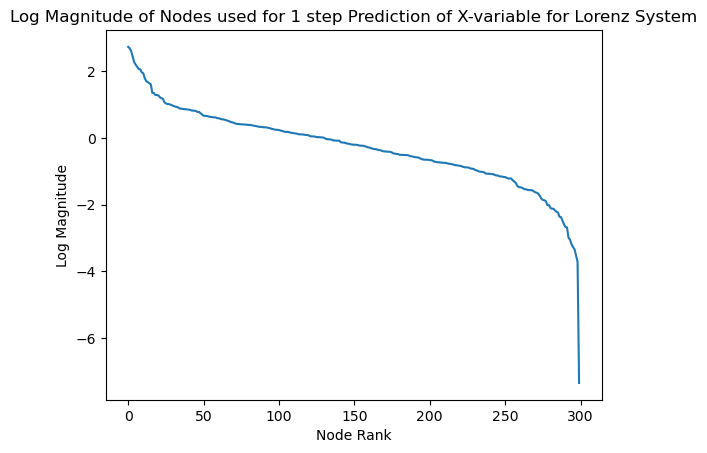

y-val area = -59.973488762032716


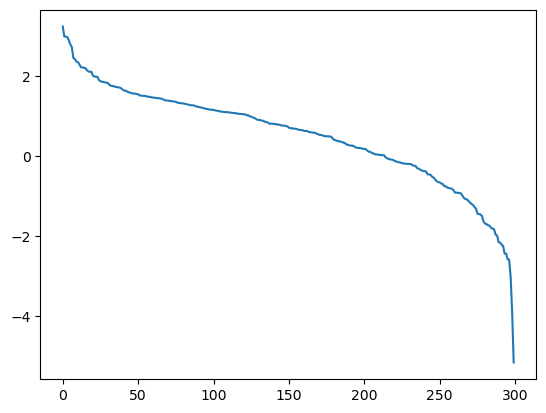

z-val area = 120.86305115942358


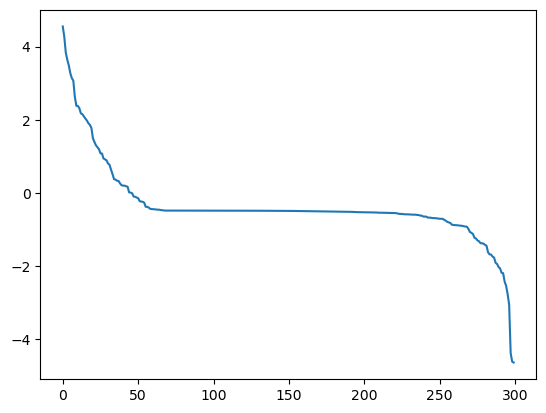

In [23]:
sig = 10 
r = 28 
b = 8/3

def lorenz_equations(matrix):
    x,y,z = matrix
    dxdt = sig * (y-x)
    dydt = r*x - x*z - y 
    dzdt = x*y - b*z
    return np.array([dxdt, dydt, dzdt])

def rk4(x0, y0, z0, t0, tf, h):
    """
    4th order runge-kutta solver
    way to approximately solve ordinary differential equations (ie. equations that model dynamical systems)
    
    :param x,y,z,0: initial value
    :param t0: initial time
    :param tf: final time
    :param h: step size 
    """

    n = int((tf-t0)/h)
    original = np.array([x0,y0,z0])


    vals = [original] #list of all resulting values

    for i in range(n):

        k1 = lorenz_equations(original) * h
        k2 = lorenz_equations(original + k1/2) * h
        k3 = lorenz_equations(original + k2/2) * h
        k4 = lorenz_equations(original + k3) * h

        original = original + ((1/6)*(k1+2*k2+2*k3+k4))

        vals.append(original.copy())

    return np.array(vals) 

vals = rk4(x0=1, y0=1, z0=1,t0=0, tf=100,h=0.01)


x_vals = vals[:,0]
y_vals = vals[:,1]
z_vals = vals[:,2]

x_rmse, x_vout = calculate_metrics(esn, x_vals, np.arange(len(x_vals)), step=1)
x_area = trapezoid(x_vout)
print(f"z-val area = {x_area}")

plt.plot(np.log(np.sort(np.abs(x_vout.ravel()))[::-1]))
plt.title('Log Magnitude of Nodes used for 1 step Prediction of X-variable for Lorenz System')
plt.xlabel("Node Rank")
plt.ylabel("Log Magnitude")
plt.savefig('LorenzX_Complexity')
plt.show()

#plt.plot(np.arange(len(y_vals)), y_vals)
y_rmse, y_vout = calculate_metrics(esn, y_vals, np.arange(len(y_vals)), step=1)
y_area = trapezoid(y_vout)
print(f"y-val area = {y_area}")

plt.plot(np.log(np.sort(np.abs(y_vout.ravel()))[::-1]))
plt.show()

#plt.plot(np.arange(len(z_vals)), z_vals)
z_rmse, z_vout = calculate_metrics(esn, z_vals, np.arange(len(z_vals)), step=1)
z_area = trapezoid(z_vout)
print(f"z-val area = {z_area}")

plt.plot(np.log(np.sort(np.abs(z_vout.ravel()))[::-1]))
plt.show()